# Reconstruction from events

Reconstructs intensity from events alone (`evcam.reconstruct`): direct integration and a high-pass filter, on events simulated from a synthetic video and on one REBlur sample. Unpolished: moved as is from the old notebook 06.

## Setup

In [7]:
import os, sys
if "google.colab" in sys.modules:
    REPO = "/content/event-perception"
    if not os.path.exists(REPO):
        !git clone https://github.com/allusson/event-perception.git {REPO}
    %cd {REPO}
    !pip install -q -e .
    sys.path.insert(0, REPO)
else:
    # local: assumes `pip install -e ".[deblur]"` was run from the repo root
    os.chdir(os.path.dirname(os.path.abspath("")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())

In [8]:
import time
import numpy as np
import matplotlib.pyplot as plt

from evcam.sources import load_reblur_clip, synthetic_video
from evcam.simulate import simulate_events
from evcam.reconstruct import direct_integration, fit_scale_offset, highpass_filter, reconstruct_e2vid
from evcam.metrics import psnr
from evcam.viz import show_images


def disp(img):
    # display only: linear intensity -> gamma 1/2.2
    return np.clip(img, 0, 1) ** (1 / 2.2)


def exposure_of(clip, i=0):
    # (t_begin, t_end, t_ref) of frame i in microseconds
    t_a, t_b = clip.exposure[i]
    return int(t_a), int(t_b), int(clip.frame_t[i])


T_NOTEBOOK = time.time()

C_SIM = 0.2                             # contrast threshold of the simulated events
HP_CUTOFF_HZ = 2.0                      # high-pass cutoff f_c
C_REAL = 0.2                            # contrast threshold assumed for real events
REBLUR_SAMPLE = ("1-3-line-100", 3)     # (sequence, index) in the REBlur test split

clip = synthetic_video(duration_s=0.5, fps=1000.0)
sim = simulate_events(clip, c=C_SIM)
print(sim.summary())

source synthetic, 346x260, 500 frames over 0.499 s, 1000 fps, 2,224,237 events over 0.499 s


## 1. Reconstruction from events only

Needs events (simulated above, or real). Both methods return a log intensity change $\hat\ell(\mathbf{x}, t)$ per pixel, starting from $\hat\ell = 0$.

**Direct integration.**

$$\hat\ell(\mathbf{x}, t) = c \sum_{k:\ \mathbf{x}_k = \mathbf{x},\ t_k \le t} p_k$$

$p_k = \pm 1$: polarity of event $k$. Any error in $c$, missed event or noise event stays in the sum, so $\hat\ell$ drifts.

**High-pass filter** (Scheerlinck et al., ACCV 2018), per pixel:

$$\frac{d\hat\ell}{dt} = \sum_k c\,p_k\,\delta(t - t_k) - \alpha\,\hat\ell, \qquad \alpha = 2\pi f_c$$

Between events $\hat\ell$ decays as $e^{-\alpha \Delta t}$; at each event it jumps by $c\,p_k$. $f_c$: cutoff frequency (`HP_CUTOFF_HZ`). Changes slower than $f_c$ are removed, including the drift and the static scene.

Neither method knows the starting log intensity of each pixel, so $\hat\ell$ shows the change since the start of the stream (direct integration) or over roughly the last $1/f_c$ (high-pass filter), not the scene itself.

**Comparison with ground truth.** Reconstructions are log intensity up to an unknown offset and scale, so before computing PSNR, $\hat I = a\,e^{\hat\ell} + b$ is fitted to the ground-truth frame by least squares over all pixels (`fit_scale_offset`). PSNR is reported over the whole frame and over the pixels whose ground-truth intensity changes during the clip (moving pixels); static pixels produce no events, so events carry no information about them. A constant image at the mean of the ground truth is the baseline.

2,224,237 events, 5 query times: direct integration 0.02 s, high-pass filter 0.02 s
SKIPPED: E2VID (E2VID is not vendored (rpg_e2vid is GPL-3.0); see reconstruct_e2vid's docstring.)


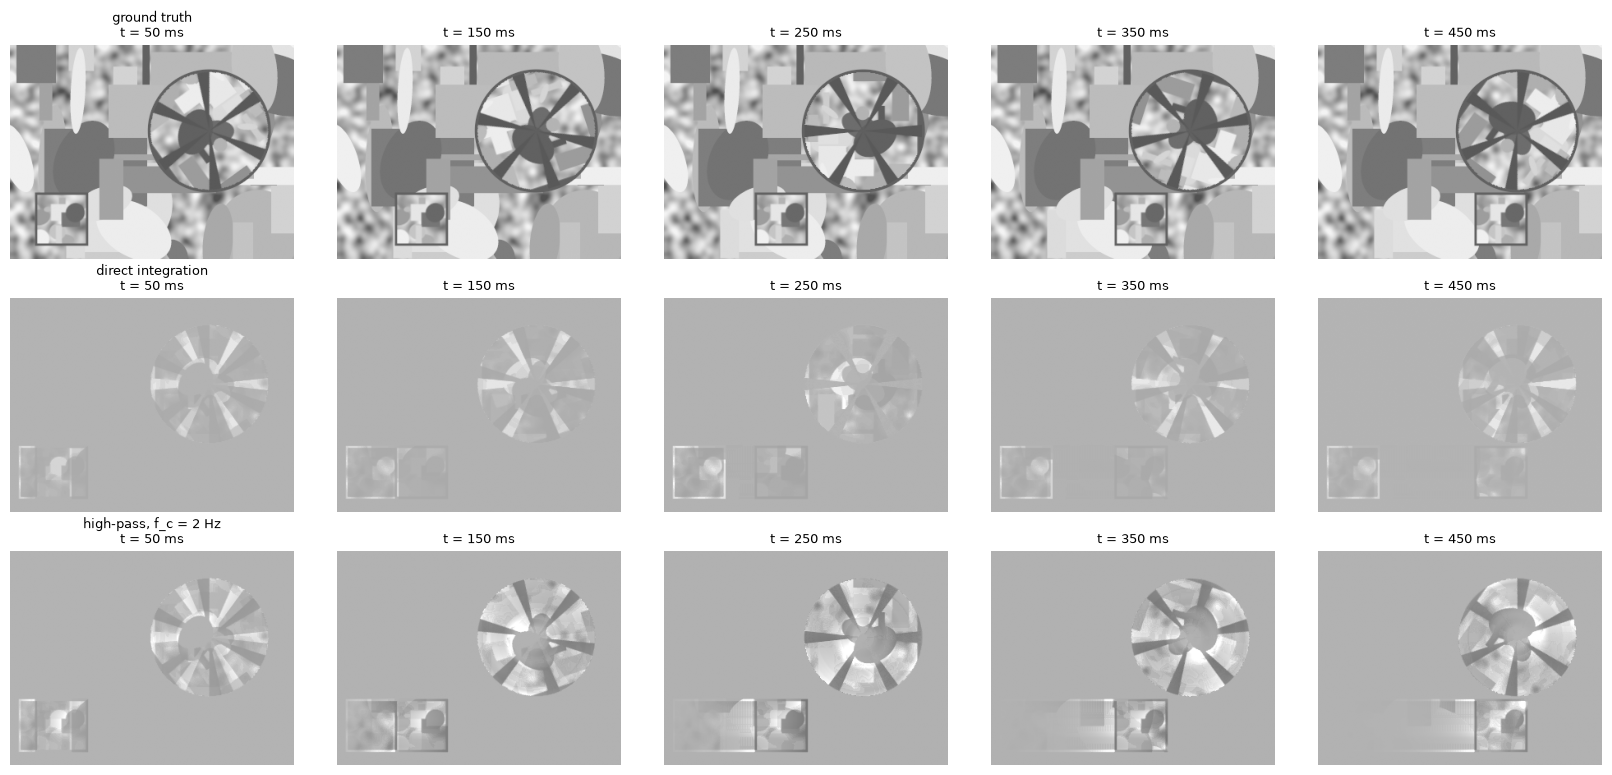

PSNR (dB) after the scale / offset fit, whole frame | moving pixels (38% of the frame)
method                             t = 50 ms        t = 150 ms        t = 250 ms        t = 350 ms        t = 450 ms
constant (mean of GT)         12.90 | 11.93    13.02 | 12.18    13.13 | 12.42    13.08 | 12.29    12.85 | 11.82
direct integration            13.10 | 12.36    13.23 | 12.64    13.36 | 12.95    13.30 | 12.82    13.06 | 12.27
high-pass, f_c = 2 Hz         13.29 | 12.78    13.82 | 14.15    14.17 | 15.26    14.11 | 15.04    13.82 | 14.15


In [9]:
ev_clip = sim if sim is not None else (clip if clip.n_events else None)
rec = {}
if ev_clip is None:
    print("SKIPPED: reconstruction needs events")
else:
    c_rec = float(np.mean(ev_clip.meta.get("c_true", C_REAL)))
    has_gt = ev_clip.n_frames > 1 and ev_clip.exposure is None       # instantaneous frames = ground truth
    if has_gt:
        q_idx = np.linspace(0.1 * ev_clip.n_frames, 0.9 * ev_clip.n_frames, 5).astype(int)
        t_q = ev_clip.frame_t[q_idx]
        gts = ev_clip.frames[q_idx]
        moving = (ev_clip.frames.max(axis=0) - ev_clip.frames.min(axis=0)) > 0.01
    else:
        t_q = np.linspace(ev_clip.events["t"][0], ev_clip.events["t"][-1], 5).astype(np.int64)
    t0 = time.time(); rec["direct integration"] = direct_integration(ev_clip.events, ev_clip.shape, c_rec, t_q)
    t1 = time.time(); rec[f"high-pass, f_c = {HP_CUTOFF_HZ:g} Hz"] = highpass_filter(ev_clip.events, ev_clip.shape, c_rec,
                                                                                     HP_CUTOFF_HZ, t_q)
    t2 = time.time()
    print(f"{ev_clip.n_events:,} events, {len(t_q)} query times: direct integration {t1 - t0:.2f} s, "
          f"high-pass filter {t2 - t1:.2f} s")
    try:
        rec["E2VID"] = reconstruct_e2vid(ev_clip.events, ev_clip.shape, t_q)
    except NotImplementedError as e:
        print(f"SKIPPED: E2VID ({e})")

    rows = ([("ground truth", [disp(g) for g in gts])] if has_gt else [])
    for name, L in rec.items():
        if has_gt:
            rows.append((name, [disp(fit_scale_offset(L[q], gts[q])[0]) for q in range(len(t_q))]))
        else:
            rows.append((name, [np.clip((L[q] + 1.5) / 3, 0, 1) for q in range(len(t_q))]))
    fig, ax = plt.subplots(len(rows), len(t_q), figsize=(3.3 * len(t_q), 2.6 * len(rows)), squeeze=False)
    for r, (name, imgs) in enumerate(rows):
        for q, img in enumerate(imgs):
            ax[r, q].imshow(img, cmap="gray", vmin=0, vmax=1); ax[r, q].axis("off")
            ax[r, q].set_title(f"{name}\nt = {t_q[q] / 1e3:.0f} ms" if q == 0 else f"t = {t_q[q] / 1e3:.0f} ms", fontsize=9)
    plt.tight_layout(); plt.show()

    if has_gt:
        def psnr_mask(img, ref, m):
            return float(10 * np.log10(1 / np.mean((img[m] - ref[m]) ** 2)))
        print(f"PSNR (dB) after the scale / offset fit, whole frame | moving pixels ({moving.mean():.0%} of the frame)")
        print(f"{'method':<26}" + "".join(f"{f't = {t / 1e3:.0f} ms':>18}" for t in t_q))
        base = [np.full_like(g, g.mean()) for g in gts]
        for name, imgs in [("constant (mean of GT)", base)] + \
                [(k, [fit_scale_offset(L[q], gts[q])[0] for q in range(len(t_q))]) for k, L in rec.items()]:
            print(f"{name:<26}" + "".join(f"{psnr(im, g):>9.2f} | {psnr_mask(im, g, moving):>5.2f}"
                                          for im, g in zip(imgs, gts)))

Drift. With the ideal simulated events, direct integration recovers the log intensity change exactly up to the quantization by $c$. The cell below simulates a second set of events with per-pixel thresholds drawn from $\mathcal N(c, 0.03^2)$ and $10^5$ noise events per second over the sensor, reconstructs both sets with the nominal $c$ at 50 times, and plots the RMS of $\hat\ell$ over the static pixels, where the true change is 0. The image on the right is direct integration of the non-ideal events at the last time.

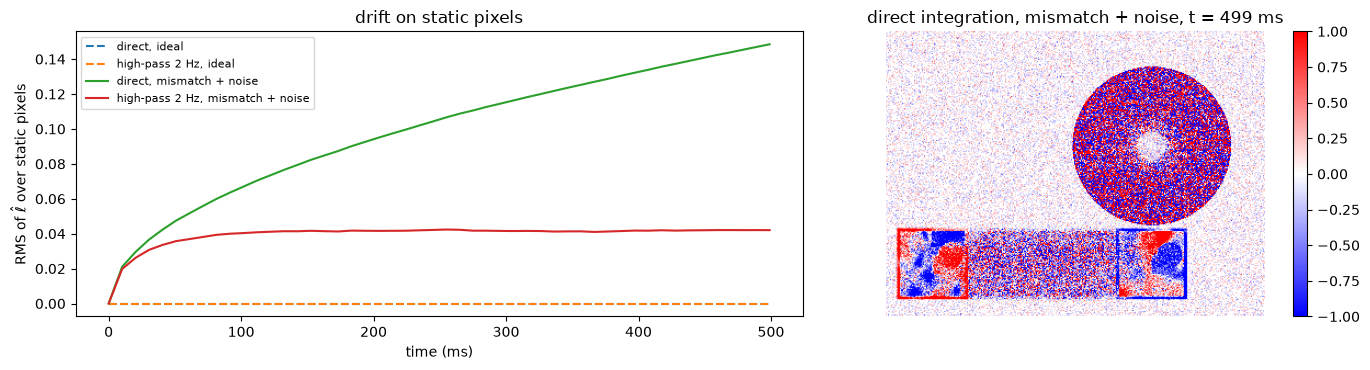

In [10]:
if ev_clip is None or sim is None or not has_gt:
    print("SKIPPED: the drift comparison needs simulated events and ground-truth frames")
else:
    noisy = simulate_events(clip, c=C_SIM, c_sigma=0.03, noise_rate_hz=1e5, seed=1)
    t_d = np.linspace(clip.frame_t[0], clip.frame_t[-1], 50).astype(np.int64)
    static = ~moving
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
    for label, ev, ls in (("ideal", sim.events, "--"), ("mismatch + noise", noisy.events, "-")):
        for name, L in (("direct", direct_integration(ev, clip.shape, C_SIM, t_d)),
                        (f"high-pass {HP_CUTOFF_HZ:g} Hz", highpass_filter(ev, clip.shape, C_SIM, HP_CUTOFF_HZ, t_d))):
            ax[0].plot(t_d / 1e3, np.sqrt(np.mean(L[:, static] ** 2, axis=1)), ls, label=f"{name}, {label}")
    D_last = direct_integration(noisy.events, clip.shape, C_SIM, t_d[-1:])[0]
    ax[0].set_xlabel("time (ms)"); ax[0].set_ylabel(r"RMS of $\hat\ell$ over static pixels")
    ax[0].set_title("drift on static pixels"); ax[0].legend(fontsize=8)
    im = ax[1].imshow(D_last, cmap="bwr", vmin=-1, vmax=1); plt.colorbar(im, ax=ax[1])
    ax[1].set_title(f"direct integration, mismatch + noise, t = {t_d[-1] / 1e3:.0f} ms"); ax[1].axis("off")
    plt.tight_layout(); plt.show()

## 2. Real data: REBlur

 One test sample: the blurry and sharp DAVIS frames and the reconstruction from the events of the exposure at its midpoint, with $c$ = `C_REAL`. The events cover only the exposure, so $\hat\ell$ is the change since the exposure start. PSNR after the scale / offset fit against the sharp frame.

source reblur, 320x260, 1 frames over 0.000 s, 47,232 events over 0.046 s


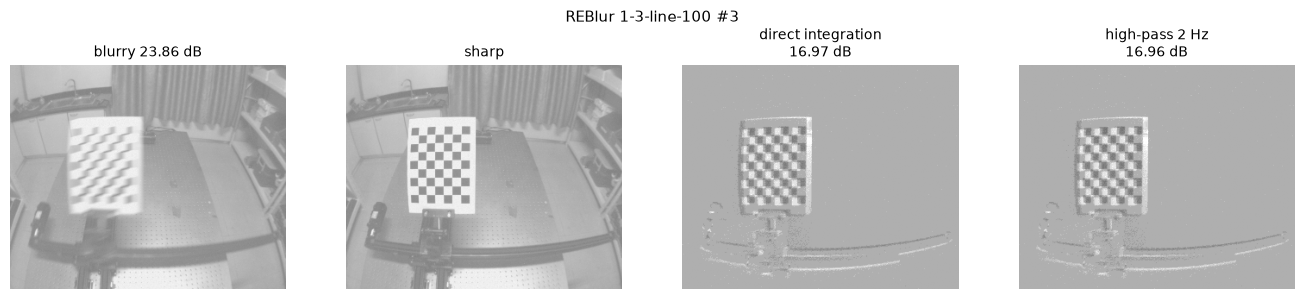

In [11]:
if not os.path.isdir("data/reblur/REBlur"):
    print("SKIPPED: REBlur not found (python scripts/download_data.py reblur)")
else:
    rb = load_reblur_clip(*REBLUR_SAMPLE)
    t_a, t_b, t_mid = exposure_of(rb)
    sharp = rb.meta["sharp"]
    imgs, titles = [disp(rb.frames[0]), disp(sharp)], [f"blurry {psnr(rb.frames[0], sharp):.2f} dB", "sharp"]
    for name, L in (("direct integration", direct_integration(rb.events, rb.shape, C_REAL, [t_mid])[0]),
                    (f"high-pass {HP_CUTOFF_HZ:g} Hz", highpass_filter(rb.events, rb.shape, C_REAL, HP_CUTOFF_HZ, [t_mid])[0])):
        fitted = fit_scale_offset(L, sharp)[0]
        imgs.append(disp(fitted)); titles.append(f"{name}\n{psnr(fitted, sharp):.2f} dB")
    print(rb.summary())
    show_images(imgs, titles, figsize_per=(3.4, 3.0), suptitle=f"REBlur {REBLUR_SAMPLE[0]} #{REBLUR_SAMPLE[1]}")
    plt.show()

In [12]:
print(f"notebook runtime {time.time() - T_NOTEBOOK:.0f} s")

notebook runtime 2 s
